В датасете находятся изображения со штрих-кодами в директории images.

Ground-truth разметка находится в файле annotations.tsv, пояснения, как читать файл, находится в README.md.

Подсказки:

В Граунд-тру штрих коды размечены как прямоугольники - координаты угла и размеры прямоугольника. Это означает, в отличие от примера в лекции, лучше использовать boundingRect
В качестве критерия правдоподобия предлагается использовать IOU.
Хорошим результатом является 0.8 для всех изображений
Штрих-код характеризуется набором вертикальных линий - вам может пригодится градиент, для выделения таких линий.

Датасет для распознавания штрих-кодов
В папке images лежат собранные на Толоке фотографии со штрих-кодами.

В файле annotations.tsv лежит разметка этих изображений. В ней указаны:

filename - относительный путь до изображения (вида images/), к которому относится аннотация.
code - код штрих-кода, находящегося внутри ограничивающего бокса.
x_from - минимальная координата ограничивающего бокса по оси x.
y_from - минимальная координата ограничивающего бокса по оси y.
width - ширина ограничивающего бокса.
height - высота ограничивающего бокса.
Чтобы прочитать annotations.tsv, пишем:

import pandas as pd


df = pd.read_csv('annotations.tsv', sep=',')

In [1]:
import cv2

In [2]:
import os

In [14]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 3.2 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.5 MB 4.0 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.5 MB 3.6 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.5 MB 3.7 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.5 MB 4.0 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.5 MB 4.3 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.5 MB 4.1 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.5 MB 4.0 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.5 MB 4.1 MB/s eta 0:00:01
   ------------------------------------ --- 8.7/9.5 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 4.1 MB/s  0:00:02
   -------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('annotations.tsv', sep=',')

In [5]:
df

,filename,x_from,y_from,width,height
0,images/0b56af7e-386c-410a-8f46-74350f755d77--r...,216,474,409,308
1,images/6e042372-20ec-4a26-8340-3653cf0c681d--r...,23,849,230,125
2,images/788fb7f3-e813-4754-874f-3cc6eb19113d--r...,322,632,344,145
3,images/d05d50c0-0c19-4ca4-88ff-6f7058318a7f--r...,516,694,325,156
4,images/93cda132-8b66-476a-a112-8acf47658fee--r...,200,474,531,292
...,...,...,...,...,...
71,images/cce85bf0-1dab-4e3f-8837-ba09bd25a20d--r...,240,537,345,177
72,images/b5c905af-95d7-4a15-abac-3ec01e01ff51--r...,155,454,522,283
73,images/4296efb5-f449-45bd-9d4a-2e63aed1940e--r...,340,672,430,287
74,images/a751736c-6631-4ece-b5ba-e887799810a5--r...,271,547,386,134


In [ ]:
def iou(box1, box2):
    """
    box1, box2: (x, y, w, h) — левый верхний угол + ширина/высота
    Возвращает IoU (0..1)
    """
    x1, y1, w1, h1 = box1
    x2, y2, w2, h2 = box2
    
    # Правые нижние углы
    x1_max, y1_max = x1 + w1, y1 + h1
    x2_max, y2_max = x2 + w2, y2 + h2
    
    # Пересечение
    inter_x1 = max(x1, x2)
    inter_y1 = max(y1, y2)
    inter_x2 = min(x1_max, x2_max)
    inter_y2 = min(y1_max, y2_max)
    
    inter_w = max(0, inter_x2 - inter_x1)
    inter_h = max(0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h
    
    # Объединение
    area1 = w1 * h1
    area2 = w2 * h2
    union_area = area1 + area2 - inter_area
    
    if union_area == 0:
        return 0.0
    return inter_area / union_area


IoU тест (ожидаем ~0.142): 0.143
IoU идентичных (ожидаем 1.0): 1.0


Размер: (1333, 1000, 3)


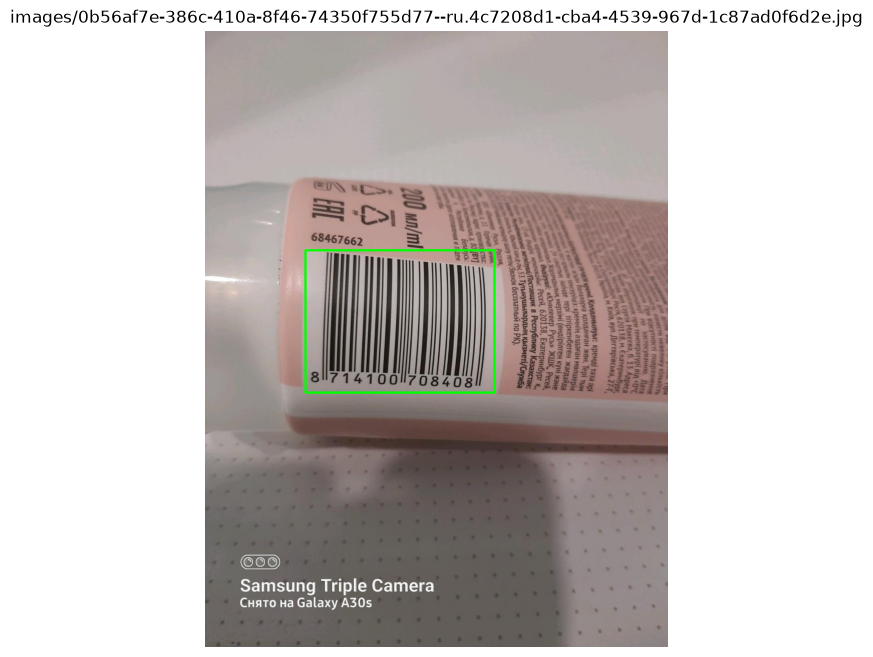

In [17]:
#для проверки
row = df.iloc[0]
filename = row['filename']                    
gt_box = (int(row['x_from']), int(row['y_from']),
          int(row['width']), int(row['height'])) #коорд настоящ штрихкода из файла с разметкой
img = cv2.imread(filename)                   
print("Размер:", img.shape)

out = img.copy()
x, y, w, h = gt_box
cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 3)
#out - на нем рисовать
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.title(filename)
plt.axis('off')
plt.show()

Пайплайн

Штрихкод - набор вертикальных чёрных полос на белом фоне 

1. grayscale - чб

2. Размытие — убрать шум
3. Градиент по оси X - максимален именно на границах вертикальных полос (переход чёрное белое)

4. Бинаризация градиента - белые полосы на чёрном фоне там, где есть перепады

5. Морфологическое закрытие горизонтальным ядром - склеивает отдельные вертикальные полосы в 1 сплошной прямоугольный блок

6. Поиск контуров - кандидаты

7. Фильтрация и выбор 

grayscale + размытие

Размер: (1333, 1000, 3)


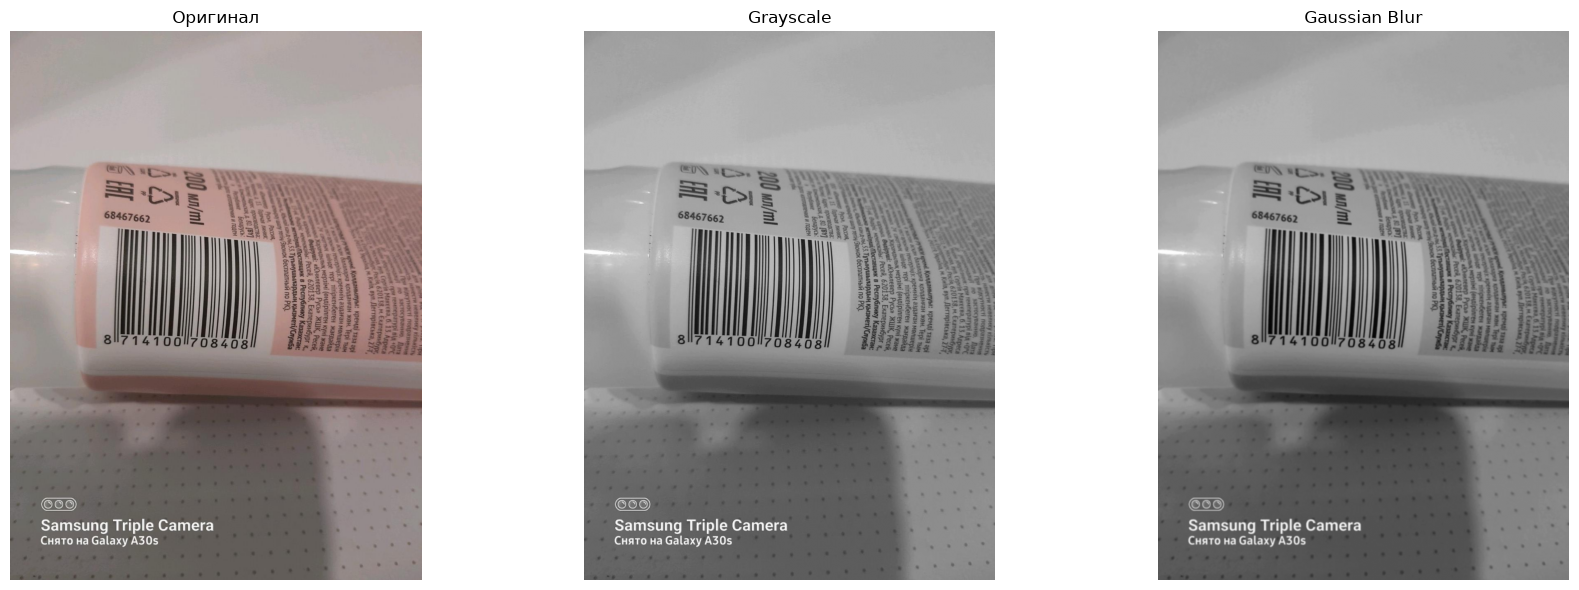

In [ ]:
row = df.iloc[0]
filename = row['filename']
gt_box = (int(row['x_from']), int(row['y_from']),
          int(row['width']), int(row['height']))

img = cv2.imread(filename)
print("Размер:", img.shape)

#grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#размытие по Гауссу (без шума, сглаживание)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title('Оригинал')
axes[1].imshow(gray, cmap='gray')
axes[1].set_title('Grayscale')
axes[2].imshow(blur, cmap='gray')
axes[2].set_title('Gaussian Blur')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Градиент по х (Собель)

Перепад яркости - по горизонтали

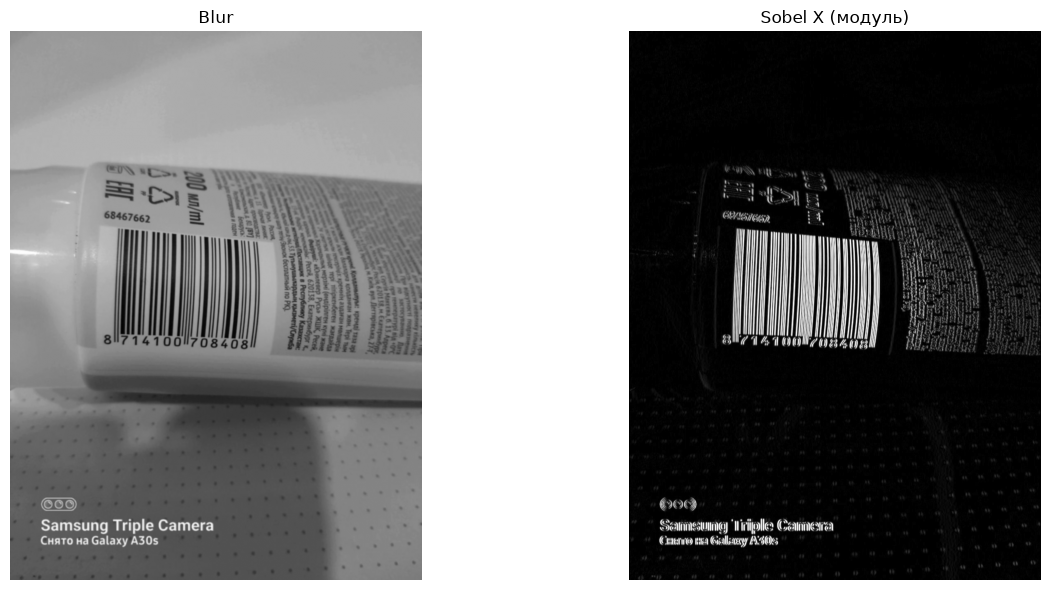

Мин/макс градиента: 0 255


In [21]:
# cv2.CV_32F - не терять отрицательные знач

grad_x = cv2.Sobel(blur, cv2.CV_32F, dx=1, dy=0, ksize=3)

#величина перепада
grad_x_abs = cv2.convertScaleAbs(grad_x)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(blur, cmap='gray')
axes[0].set_title('Blur')
axes[1].imshow(grad_x_abs, cmap='gray')
axes[1].set_title('Sobel X (модуль)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print("Мин/макс градиента:", grad_x_abs.min(), grad_x_abs.max())

Бинаризация градиента

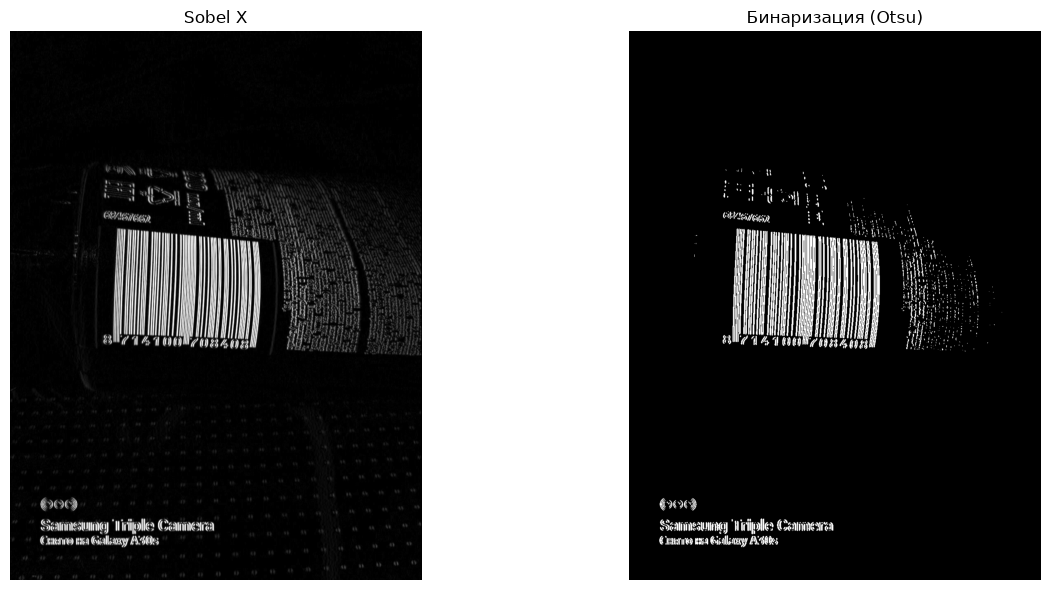

In [ ]:
# Otsu автоматически подбирает порог
_, binary = cv2.threshold(grad_x_abs, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(grad_x_abs, cmap='gray')
axes[0].set_title('Sobel X')
axes[1].imshow(binary, cmap='gray')
axes[1].set_title('Бинаризация (Otsu)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Морфологическое закрытие (склейка полос)

Ядро - горизонтальное (широкое по х, узкое по у)

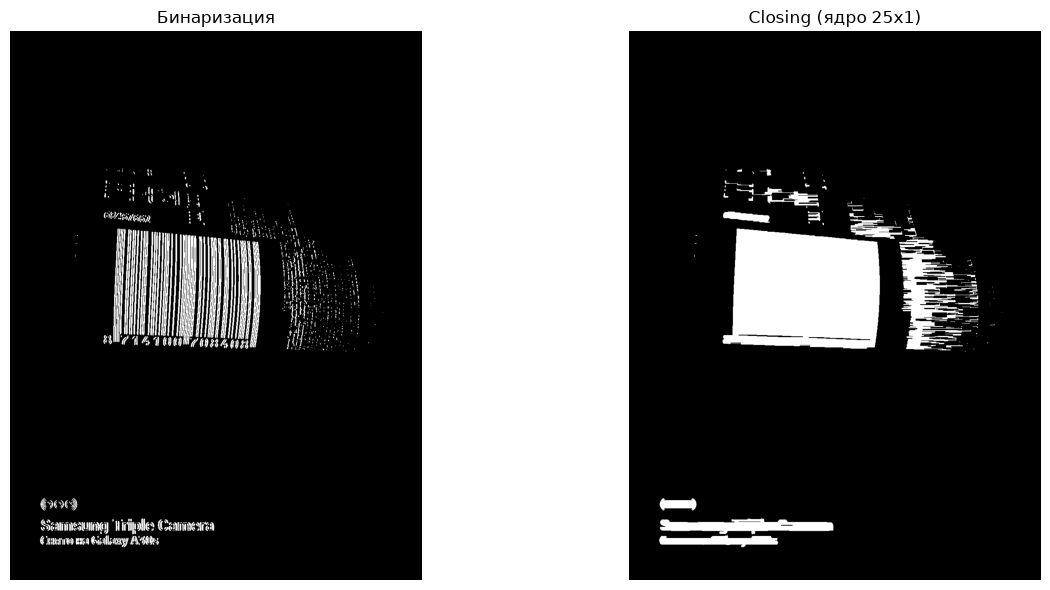

In [ ]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 1))

#расширяются белые области (склеивание), сужение обратно
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(binary, cmap='gray')
axes[0].set_title('Бинаризация')
axes[1].imshow(closed, cmap='gray')
axes[1].set_title('Closing (ядро 25x1)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Поиск контуров

Найдено контуров: 97


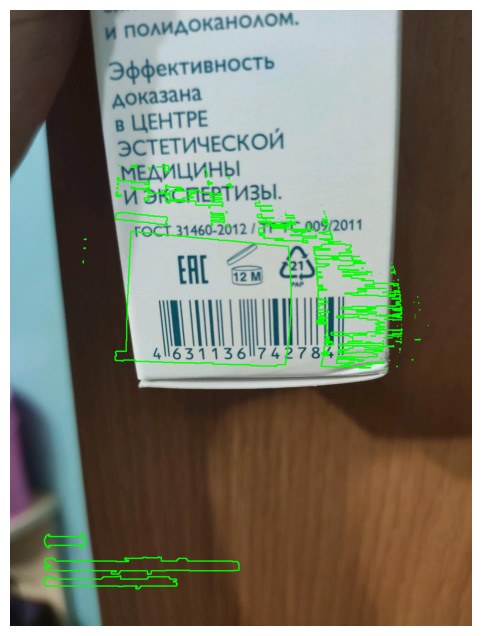

In [120]:
contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) #только внешние границы;сжатие контура+уборка точек

print(f"Найдено контуров: {len(contours)}")

img_contours = img.copy()
cv2.drawContours(img_contours, contours, -1, (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Фильтрация и выбор

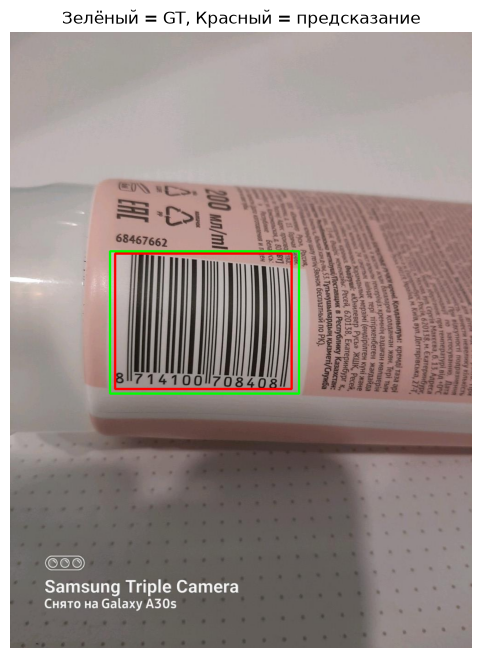


IoU: 0.8885


In [ ]:
# контур с максимальной площадью
if len(contours) == 0:
    pred_box = None
else:
    best_contour = max(contours, key=cv2.contourArea)
    pred_box = cv2.boundingRect(best_contour)

if pred_box is not None:
    img_result = img.copy()
    x, y, w, h = gt_box
    cv2.rectangle(img_result, (x, y), (x + w, y + h), (0, 255, 0), 4)   
    px, py, pw, ph = pred_box
    cv2.rectangle(img_result, (px, py), (px + pw, py + ph), (0, 0, 255), 4)  
    
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
    plt.title('красный - предсказание')
    plt.axis('off')
    plt.show()
    
    # IoU
    score = iou(gt_box, pred_box)
    print(f"\nIoU: {score:.4f}")

Функция полный пайплайн

In [90]:
def detect_barcode(img):

    # 1) Grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # 2) Размытие (без шума)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # 3) Градиент по х (вертикальные полосы)
    grad_x = cv2.Sobel(blur, cv2.CV_32F, dx=1, dy=0, ksize=3)
    grad_x_abs = cv2.convertScaleAbs(grad_x)
    
    # 4) Бинаризация (Otsu)
    _, binary = cv2.threshold(grad_x_abs, 0, 255,
                              cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # 5) Морфологическое закрытие горизонтальным ядром (склейка полос)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 1))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    
    # 6) Поиск контуров
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    
    # 7) Выбор самого крупного контура
    best = max(contours, key=cv2.contourArea)
    return cv2.boundingRect(best)

Цикл по всему датасету 

In [ ]:
scores = []
failed = []

for _, row in df.iterrows():
    filename = row['filename']
    gt_box = (int(row['x_from']), int(row['y_from']),
              int(row['width']), int(row['height']))
    
    img = cv2.imread(filename)
    if img is None:
        failed.append(filename)
        scores.append(0.0)
        continue
    
    pred_box = detect_barcode(img)
    if pred_box is None:
        failed.append(filename)
        scores.append(0.0)
        continue
    
    scores.append(iou(gt_box, pred_box))

scores = np.array(scores)

# Итоговая статистика
print(f"Средний IoU: {scores.mean():.4f}")
print(f"Медиана IoU: {np.median(scores):.4f}")

Средний IoU: 0.6863
Медиана IoU: 0.8853


Средний IoU должен быть >=0.8

Поиск плохих картинок

In [95]:
bad = []
for _, r in df.iterrows():
    img = cv2.imread(r['filename'])
    pred = detect_barcode(img) if img is not None else None
    gt = (r['x_from'], r['y_from'], r['width'], r['height'])
    s = iou(gt, pred) if pred else 0.0
    if s < 0.5:
        bad.append((s, r['filename']))

bad.sort()


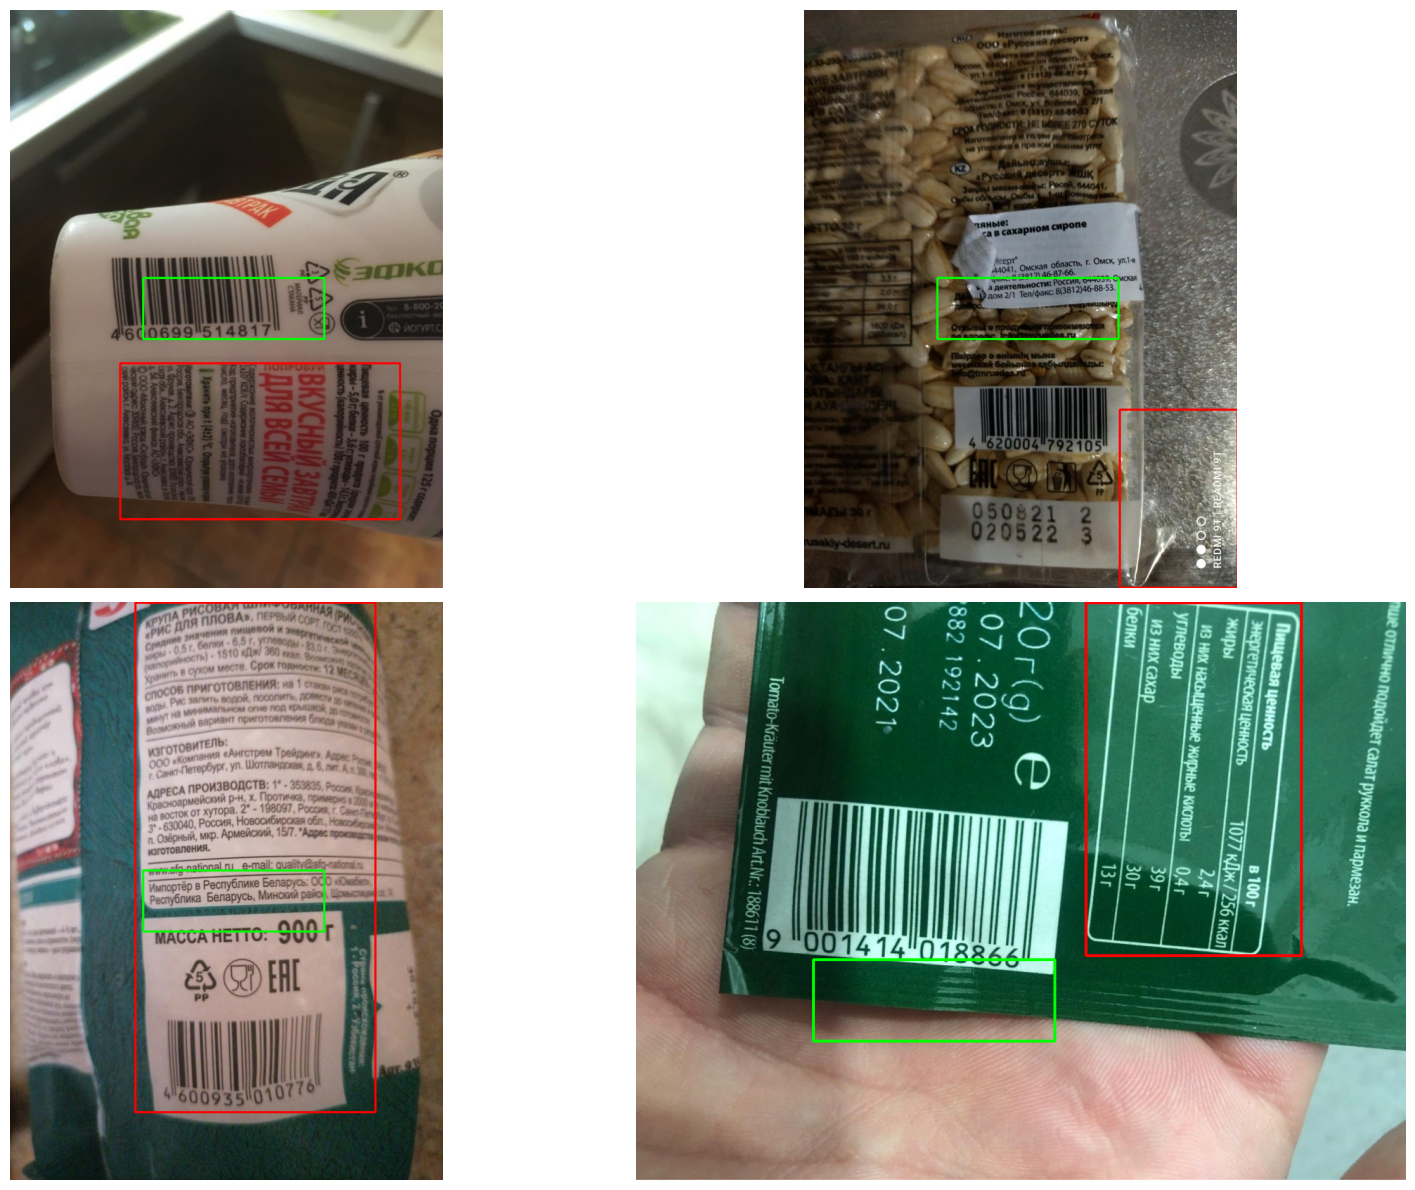

In [ ]:
worst = bad[:4]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for i, (s, f) in enumerate(worst):
    img = cv2.imread(f)
    gx, gy, gw, gh = gt
    cv2.rectangle(img, (gx, gy), (gx+gw, gy+gh), (0, 255, 0), 4)  
    
    pred = detect_barcode(img)
    if pred:
        px, py, pw, ph = pred
        cv2.rectangle(img, (px, py), (px+pw, py+ph), (0, 0, 255), 4)  
    
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Улучшение выбора

area - штрихкод (крупный объект),
density - плотный прямоугольник, v_score - состоит из вертикальных полос

In [ ]:
def detect_barcode(img):
    H, W = img.shape[:2]

    #1) grayscale и размытие
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    #2) градиент по х (вертик полосы штрихкода)
    gx = cv2.convertScaleAbs(cv2.Sobel(blur, cv2.CV_32F, 1, 0, ksize=3))

    #3) Оцу
    _, binary = cv2.threshold(gx, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    #4) склеивание вертикальных полос в блок
    kw = max(15, min(40, int(W * 0.02)))
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kw, 1))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    #5) поиск контура
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None

    #6) выбор 
    best_box, best_score = None, -1
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w < 10 or h < 10:
            continue
        if w > 0.9 * W or h > 0.9 * H:
            continue
        area = cv2.contourArea(c)
        density = area / (w * h)
        roi = binary[y:y+h, x:x+w]
        v_score = roi.sum() / 255 / (w * h)
        score = area * density * v_score
        if score > best_score:
            best_score, best_box = score, (x, y, w, h)
    return best_box

In [118]:
scores = []
for _, r in df.iterrows():
    img = cv2.imread(r['filename'])
    pred = detect_barcode(img) if img is not None else None
    gt = (int(r['x_from']), int(r['y_from']), int(r['width']), int(r['height']))
    scores.append(iou(gt, pred) if pred else 0.0)

scores = np.array(scores)
print(f"Средний IoU: {scores.mean():.4f}")


Средний IoU: 0.8161


Средний IoU: 0.8161

Выбор крупного контура оказывался не штрихкодом, а этикеткой. Ослабление фильтра размера дало улучшение